> Notebook-friendly copy of `part-III/6.3-land-cover-classification-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch", "torchmetrics": "torchmetrics"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 6.3) (Exercise) Land Cover Classification
![EuroSAT overview image](https://raw.githubusercontent.com/phelber/EuroSAT/master/eurosat_overview_small.jpg)

This notebook is converted from the source: https://www.coursera.org/learn/getting-started-with-tensor-flow2

**🎯 Learning objectives**

- Construct CNNs that classify EuroSAT images into one of 10 land use classes
- Save and load trained models
- Improve the performance of the model

**Land Cover Classification** aims to automatically provide labels describing the represented physical land type or how a land area is used (e.g., residential, industrial).   

**Convolutional Neural Networks (CNNs)**,  the state of-the-art image classification method in computer vision and machine learning, have been reported to be suitable for the classification of remotely sensed
images.

However, the classification of remotely sensed images is a challenging task, particularly due to the lack of reliably labeled ground truth datasets.

The [EuroSAT dataset](https://github.com/phelber/EuroSAT) provides large quantity of training data for this purpose. It consists of 27000 labelled Sentinel-2 satellite images of different land uses: residential, industrial, highway, river, forest, pasture, herbaceous vegetation, annual crop, permanent crop and sea/lake.

For a reference, see the following papers:
- Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification. Patrick Helber, Benjamin Bischke, Andreas Dengel, Damian Borth. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 2019.
- Introducing EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification. Patrick Helber, Benjamin Bischke, Andreas Dengel. 2018 IEEE International Geoscience and Remote Sensing Symposium, 2018.



---




You can **create your own code** by following each question **or complete the code with blanks**.


---

In [2]:
# Run this cell first to import all required packages.
import torch
import torch.nn as nn
from collections import OrderedDict

In [3]:
import torchvision

In [4]:
import torchmetrics
from sklearn.model_selection import train_test_split

In [5]:
import os
import glob
import tarfile
import pooch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# If you would like to make further imports from torch or torchvision, add them here

## Data Setup

Using the EuroSAT dataset which consists of 27000 images and labels might use too much memory, thus we use a smaller subset of the original dataset - 4000 training images and 1000 testing images with roughly equal numbers of each class.

In [6]:
# Run this cell to fetch and reassemble the dataset
chunk_suffixes = ["aa", "ab"]
chunk_hashes = {
    "aa": "ce9f73e68261a010956eeb73876f047f35a25986b037694cd08cc0a837418f3c",
    "ab": "b87e1a0b9da3e69579723103a4934d1b0bbb518d3d1a0d11f51b5ff75db56e25",
}
cache_dir = pooch.os_cache("mlees")
chunk_paths = [
    pooch.retrieve(
        url=f"https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-III/data_cnn.zip.part{suffix}",
        known_hash=f"sha256:{chunk_hashes[suffix]}",
        fname=f"data_cnn.zip.part{suffix}",
        path=cache_dir,
    )
    for suffix in chunk_suffixes
]

In [7]:
data_cnn_archive = os.path.join(cache_dir, "data_cnn.zip")
if not os.path.exists(data_cnn_archive):
    with open(data_cnn_archive, "wb") as out_f:
        for chunk_path in chunk_paths:
            with open(chunk_path, "rb") as in_f:
                out_f.write(in_f.read())
    import zipfile
    with zipfile.ZipFile(data_cnn_archive) as z:
        z.extractall(cache_dir)

In [8]:
data_cnn_dir = os.path.join(cache_dir, "data_cnn")

In [9]:
# Import the Eurosat data
def load_eurosat_data():
    x_train = np.load(os.path.join(data_cnn_dir, 'x_train.npy'))
    y_train = np.load(os.path.join(data_cnn_dir, 'y_train.npy'))
    x_val  = np.load(os.path.join(data_cnn_dir, 'x_test.npy'))
    y_val  = np.load(os.path.join(data_cnn_dir, 'y_test.npy'))
    return (x_train, y_train), (x_val, y_val)

In [10]:
(X_train, y_train), (X_val_test, y_val_test) = load_eurosat_data()
X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)

In [11]:
# Normalize data, move the channel dimension to PyTorch's expected position
# (channels first), and convert everything to tensors
def to_tensor(X, y):
    X = torch.tensor(X / 255.0, dtype=torch.float32).permute(0, 3, 1, 2)
    y = torch.tensor(y, dtype=torch.long).reshape(-1)  # (N, 1) -> (N,)
    return X, y

In [12]:
X_train, y_train = to_tensor(X_train, y_train)
X_val, y_val = to_tensor(X_val, y_val)
X_test, y_test = to_tensor(X_test, y_test)

Since PyTorch has no `.compile()`/`.fit()`/`.evaluate()`, we'll define three small reusable helpers before building any models — one to train a model for a number of epochs (optionally with callbacks and a validation set), one to evaluate a model on a dataset, and a `History` class that mimics Keras's `history.history` dict-of-lists so the rest of this notebook can stay close to the original.

In [13]:
class History:
    def __init__(self):
        self.history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

In [14]:
def evaluate_model(model, X, y, batch_size=32):
    model.eval()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size)
    losses = []
    accuracy.reset()
    with torch.no_grad():
        for X_batch, y_batch in loader:
            y_pred = model(X_batch)
            losses.append(loss_fn(y_pred, y_batch).item())
            accuracy.update(y_pred, y_batch)
    return [np.mean(losses), accuracy.compute().item()]

In [15]:
def train_model(model, X, y, epochs, validation_data=None, callbacks=None, verbose=1):
    callbacks = callbacks or []
    optimizer = optimizer_class(model.parameters())
    history = History()
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=32, shuffle=True)

    for epoch in range(epochs):
        model.train()
        train_losses = []
        accuracy.reset()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
            accuracy.update(y_pred, y_batch)

        logs = {"loss": np.mean(train_losses), "accuracy": accuracy.compute().item()}
        history.history["loss"].append(logs["loss"])
        history.history["accuracy"].append(logs["accuracy"])

        report = f"Epoch {epoch + 1}/{epochs} - loss: {logs['loss']:.4f} - accuracy: {logs['accuracy']:.4f}"
        if validation_data is not None:
            val_loss, val_accuracy = evaluate_model(model, *validation_data)
            logs["val_loss"], logs["val_accuracy"] = val_loss, val_accuracy
            history.history["val_loss"].append(val_loss)
            history.history["val_accuracy"].append(val_accuracy)
            report += f" - val_loss: {val_loss:.4f} - val_accuracy: {val_accuracy:.4f}"
        if verbose:
            print(report)

        stop_training = False
        for callback in callbacks:
            if callback.on_epoch_end(epoch, model, logs) == "stop":
                stop_training = True
        if stop_training:
            break

    return history

## Q1 Build a CNN `model1` to classify Eurosat data.

Let's construct a CNN called `model1` using `nn.Sequential`, according to the following specifications:

* The first layer should be a `Conv2d` layer with 16 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_1'.
* Follow it with a `ReLU` activation, named 'relu_1'.
* The third layer should also be a `Conv2d` layer with 8 filters, a 3x3 kernel size, and 'same' padding. Name this layer 'conv_2'.
* Follow it with a `ReLU` activation, named 'relu_2'.
* The fifth layer should be a `MaxPool2d` layer with a pooling window size of 8x8. Name this layer 'pool_1'.
* The sixth layer should be a `Flatten` layer, named 'flatten'.
* The seventh layer should be a `Linear` layer with 32 units, followed by a `ReLU` activation. Name these layers 'dense_1' and 'relu_3'.
* The final layer should be a `Linear` layer with 10 units and no activation (unlike Keras, `nn.CrossEntropyLoss` expects raw logits, not softmax probabilities). Name this layer 'dense_2'.

*Hint 1: Unlike `keras.models.Sequential`, `nn.Sequential` doesn't have an `.add()` method — but if you pass it an [`OrderedDict`](https://docs.python.org/3/library/collections.html#collections.OrderedDict) of `(name, layer)` pairs, you get the same named-layer access (`model1.conv_1`, etc.) that Keras's `name=` argument gives you.*

*Hint 2: `nn.Conv2d` needs an explicit number of input channels — 3 for the first layer (RGB), and `conv_2`'s input channels equal `conv_1`'s output channels.*

*Hint 3: As in the artificial-neural-networks and deep-computer-vision exercises, [`nn.LazyLinear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.LazyLinear.html) can save you from computing the flattened size by hand.*

In [16]:
# input_shape = (channels, height, width): on prend tout sauf la dimension du batch (axe 0).
# X_train a la forme (N, C, H, W) après le permute fait dans to_tensor().
input_shape = X_train.shape[1:]
print(input_shape)  # attendu : torch.Size([3, 64, 64])

torch.Size([3, 64, 64])


In [17]:
# Construction du modèle : OrderedDict => couches nommées (model1.conv_1, etc.)
model1 = nn.Sequential(OrderedDict([
    # 3 canaux d'entrée (RGB) -> 16 filtres ; padding="same" garde la taille 64x64
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    # entrée = sortie de conv_1 (16 canaux) -> 8 filtres
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    # pooling 8x8 : 64x64 -> 8x8 (réduit fortement la dimension spatiale)
    ("pool_1", nn.MaxPool2d((8, 8))),
    # (8 canaux, 8, 8) -> vecteur de 512 valeurs
    ("flatten", nn.Flatten()),
    # LazyLinear : la taille d'entrée (512) est déduite au premier passage
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    # 10 classes EuroSAT, pas d'activation : CrossEntropyLoss attend des logits
    ("dense_2", nn.LazyLinear(10)),
]))

In [18]:
# Run one batch through the model to materialize the LazyLinear layers
model1(X_train[:1])

tensor([[-0.0911,  0.0038,  0.0570,  0.0676,  0.0210,  0.0074, -0.0545,  0.1924,
          0.1322,  0.0091]], grad_fn=<AddmmBackward0>)

In [19]:
print(sum(p.numel() for p in model1.parameters()))  # attendu : 18354

18354


❓❓❓ Do you have a model of the following structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model1-summary-reference.jpg?raw=1'> </center>

*(This screenshot is from the original Keras version of this exercise — `print(model1)` will show a differently formatted, but structurally equivalent, layer list.)*

## Q2 Set up `model1`'s loss function, optimizer, and an evaluation metric.

* Use the Adam optimiser, cross entropy loss function, and a single accuracy metric.

In [20]:
loss_fn = nn.CrossEntropyLoss()  # classification multi-classes, labels entiers, sorties = logits
optimizer_class = torch.optim.Adam  # classe (pas instance) : train_model l'instancie avec model.parameters()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10)  # 10 classes EuroSAT

## Q3 Evaluate the initial accuracy of `model1`: Is the initial accuracy of the model as you have expected?

In [21]:
# Précision d'un modèle non entraîné (poids aléatoires), sur le jeu de test
test_loss, test_acc = evaluate_model(model1, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=test_acc))

Test accuracy: 0.116


In [ ]:
# Answer (Q3): yes, the initial accuracy is similar to the reference: ~0.11 (loss ~2.33).
#
# Why? At initialization, the weights are random: the network has not learned anything yet
# and its predictions have no relation to the true classes. With 10 roughly balanced
# classes, it behaves like random guessing, so:
#   - accuracy ~ 1/10 = 0.10 (0.11 here; the small gap comes from chance and the limited
#     number of test images)
#   - loss ~ ln(10) ~ 2.30: this is the cross-entropy of a model that assigns ~10% probability
#     to each class (2.33 here, very close)
#
# This is a good sanity check before training: if the initial loss were far from ln(10),
# something would probably be wrong (badly formatted labels, softmax applied twice, etc.).
# After training (Q5), the accuracy should clearly exceed this chance level.

❓❓❓ Does your model have a similar initial accuracy & why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-initial-accuracy-reference.jpg?raw=1'> </center>

## Q4 Train `model1` with 15 epochs, store the result in variable 'history';
* Store the fitting result in a variable history;

In [22]:
epochs = 15

history = train_model(model1, X_train, y_train,
                      epochs=epochs,
                      validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.9522 - accuracy: 0.2590 - val_loss: 1.6663 - val_accuracy: 0.3580
Epoch 2/15 - loss: 1.5061 - accuracy: 0.4207 - val_loss: 1.5026 - val_accuracy: 0.4040
Epoch 3/15 - loss: 1.3766 - accuracy: 0.4695 - val_loss: 1.3587 - val_accuracy: 0.4640
Epoch 4/15 - loss: 1.3012 - accuracy: 0.5132 - val_loss: 1.3449 - val_accuracy: 0.4740
Epoch 5/15 - loss: 1.2510 - accuracy: 0.5240 - val_loss: 1.2478 - val_accuracy: 0.5120
Epoch 6/15 - loss: 1.1809 - accuracy: 0.5440 - val_loss: 1.2295 - val_accuracy: 0.5040
Epoch 7/15 - loss: 1.1349 - accuracy: 0.5748 - val_loss: 1.1613 - val_accuracy: 0.5640
Epoch 8/15 - loss: 1.0693 - accuracy: 0.6058 - val_loss: 1.0933 - val_accuracy: 0.6080
Epoch 9/15 - loss: 1.0254 - accuracy: 0.6248 - val_loss: 1.0381 - val_accuracy: 0.6340
Epoch 10/15 - loss: 0.9625 - accuracy: 0.6445 - val_loss: 1.0034 - val_accuracy: 0.6280
Epoch 11/15 - loss: 0.9371 - accuracy: 0.6543 - val_loss: 0.9696 - val_accuracy: 0.6300
Epoch 12/15 - loss: 0.9038 - accuracy: 0.

In [ ]:
# Answer (Q4): yes, similar to the reference.
# Loss decreases (~1.9 -> ~0.8) and accuracy rises (~0.25 -> ~0.70), well above chance (0.10),
# Chance level = 1/10 = 10% accuracy (10 balanced classes, random guessing).
# Our model reaches ~70%, i.e. ~7x better than chance: it has really learned something.
# Still, 70% is far from good (the EuroSAT paper reaches 98.6%).
# so the CNN is learning useful features.
# Train and validation stay close (0.70 vs 0.68): no overfitting (low variance).
# But accuracy is still low and still improving at epoch 15: the model is too small
# (high bias / underfitting). This motivates Q9: increase the model capacity.

In [ ]:
# Bias check: training accuracy is low (~70%) and train/val are close (0.70 vs 0.68)
# -> the model underfits (high bias), it is not overfitting (that would show a large gap).
# Ways to reduce bias: bigger/deeper model (more filters, more layers), train longer,
# or use a pretrained model (transfer learning).

# on sait que ca underfit car on sait quon peut avoir un meilleur score 98 dans la'rticle

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-training-output-reference.jpg?raw=1'> </center>

*(Again, expect a differently formatted but comparable progress report — there's no Keras-style progress bar here.)*

## Q5 Evaluate the accuracy of fitted `model1`, plot training, validation set loss and accuracy, and print the model's structure

* Evaluate the fitted model
    * What's the test accuracy after training the model? Does it improve from the initialization?
* Print the model's structure

In [23]:
# Précision finale sur le jeu de test (jamais vu pendant l'entraînement)
score = evaluate_model(model1, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.666


In [ ]:
# Answer (Q5): test accuracy = 0.666, a large improvement over the initial ~0.11 (chance level).
# It is very close to the validation (0.68) and training (0.70) accuracy: the model generalizes
# to unseen data and does not overfit.
# However, ~68% is still low: the model underfits (high bias), which we try to fix in Q9.

❓❓❓ Do you have similar test accuracy?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-test-accuracy-reference.jpg?raw=1'> </center>

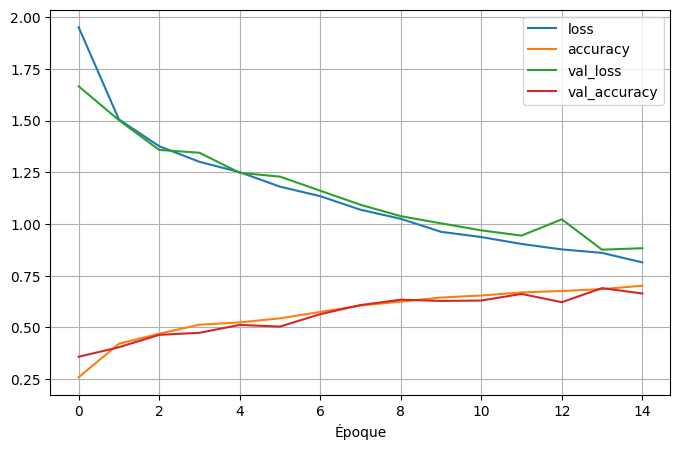

In [24]:
# history.history est un dict de listes => DataFrame (une colonne par métrique, une ligne par époque)
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.xlabel("Époque")
plt.grid(True)
plt.show()

❓❓❓ Do you have a similar plot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-loss-accuracy-plot-reference.png?raw=1'> </center>

In [ ]:
# Training and validation curves are almost superimposed: the model generalizes well and does
# not overfit (low variance). Loss is still decreasing and accuracy still increasing at epoch 14,
# but accuracy is only ~0.70: the model underfits (high bias), it has not converged and is too
# small. The small dip around epoch 12 is just noise from the small validation set (500 images).

In [25]:
print(model1)

Sequential(
  (conv_1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_1): ReLU()
  (conv_2): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (relu_2): ReLU()
  (pool_1): MaxPool2d(kernel_size=(8, 8), stride=(8, 8), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense_1): Linear(in_features=512, out_features=32, bias=True)
  (relu_3): ReLU()
  (dense_2): Linear(in_features=32, out_features=10, bias=True)
)


In [ ]:
# Same structure as the reference diagram: conv_1 (16 filters) -> conv_2 (8 filters) -> pool_1 (8x8)
# -> flatten (8*8*8 = 512) -> dense_1 (32) -> dense_2 (10 classes).
# Differences are only in the format: in PyTorch the ReLUs are separate layers and tensors are
# channels-first, e.g. (16, 64, 64) instead of (64, 64, 16).

❓❓❓ Do you have a similar structure?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model-plot-reference.jpg?raw=1'> </center>

*(This reference was generated with Keras's `plot_model` utility, which has no PyTorch equivalent — `print(model)` gives you the same layer-by-layer information as text instead of a diagram.)*

## Q6 Create two callbacks to save the model weights at each epoch and the best validation accuracy epoch

1. `checkpoint_every_epoch`: a callback that saves the model weights every epoch during training;
2. `checkpoint_best_only`: a callback that saves only the weights with the highest validation accuracy.

*Hint 1: Since `train_model` calls each callback's `on_epoch_end(epoch, model, logs)` method after every epoch, a callback here is just a small class with that one method — `logs` is the same dict of `"loss"`/`"accuracy"`/`"val_loss"`/`"val_accuracy"` values printed for that epoch.*

*Hint 2: Use [`torch.save(model.state_dict(), path)`](https://docs.pytorch.org/docs/stable/generated/torch.save.html) to save weights — there's no PyTorch equivalent of Keras's `ModelCheckpoint`, so both callbacks save with plain `torch.save()`.*

In [26]:
class CheckpointEveryEpoch:
    def __init__(self, dirpath):
        self.dirpath = dirpath
        os.makedirs(dirpath, exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        # epoch commence à 0 => checkpoint_000.pt, checkpoint_001.pt, ...
        path = os.path.join(self.dirpath, f"checkpoint_{epoch:03d}.pt")
        # on sauvegarde seulement les poids (state_dict), pas l'objet modèle entier
        torch.save(model.state_dict(), path)

checkpoint_every_epoch = CheckpointEveryEpoch(dirpath="checkpoints_every_epoch")

In [27]:
class CheckpointBestOnly:
    def __init__(self, filepath, monitor="val_accuracy"):
        self.filepath = filepath
        self.monitor = monitor
        self.best = -np.inf  # toute valeur sera meilleure à la 1re époque
        os.makedirs(os.path.dirname(filepath), exist_ok=True)

    def on_epoch_end(self, epoch, model, logs):
        # on n'écrase le fichier que si la métrique surveillée s'améliore
        if logs[self.monitor] > self.best:
            self.best = logs[self.monitor]
            torch.save(model.state_dict(), self.filepath)

In [28]:
checkpoint_best_only = CheckpointBestOnly(filepath=os.path.join("checkpoints_best_only", "checkpoint.pt"),
                                          monitor="val_accuracy")

## Q7 Build a CNN `model` with the same initial structure as `model1` and train for 15 epochs using the callbacks from Q6

Now, you will train the model using the two callbacks you created. If you created the callbacks correctly, two things should happen:
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_every_epoch`
- At the end of every epoch, the model weights are saved into a directory called `checkpoints_best_only` **only** if those weights lead to the highest validation accuracy

You should then have two directories:
- A directory called `checkpoints_every_epoch` containing filenames that include `checkpoint_000.pt`, `checkpoint_001.pt`, etc, with the numbers corresponding to the epoch
- A directory called `checkpoints_best_only` containing a single `checkpoint.pt` file, containing only the weights leading to the highest validation accuracy

In [29]:
# Create a model with the same initial structure as model1 again from scratch
model = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model(X_train[:1])

tensor([[-0.0997, -0.1698, -0.1004,  0.0574, -0.0645,  0.0086,  0.1234,  0.0511,
         -0.1292,  0.0029]], grad_fn=<AddmmBackward0>)

In [30]:
# Entraînement avec les deux callbacks : train_model appelle on_epoch_end() de chacun après chaque époque
callbacks = [checkpoint_every_epoch, checkpoint_best_only]
history = train_model(model, X_train, y_train, epochs=15, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/15 - loss: 2.0213 - accuracy: 0.2405 - val_loss: 1.6998 - val_accuracy: 0.3580
Epoch 2/15 - loss: 1.4424 - accuracy: 0.4597 - val_loss: 1.3892 - val_accuracy: 0.4660
Epoch 3/15 - loss: 1.3041 - accuracy: 0.4882 - val_loss: 1.3189 - val_accuracy: 0.4660
Epoch 4/15 - loss: 1.2517 - accuracy: 0.5203 - val_loss: 1.2240 - val_accuracy: 0.5640
Epoch 5/15 - loss: 1.1968 - accuracy: 0.5587 - val_loss: 1.2172 - val_accuracy: 0.5460
Epoch 6/15 - loss: 1.1443 - accuracy: 0.5897 - val_loss: 1.1925 - val_accuracy: 0.5480
Epoch 7/15 - loss: 1.1038 - accuracy: 0.5990 - val_loss: 1.1481 - val_accuracy: 0.5860
Epoch 8/15 - loss: 1.0678 - accuracy: 0.6175 - val_loss: 1.1570 - val_accuracy: 0.5760
Epoch 9/15 - loss: 1.0439 - accuracy: 0.6283 - val_loss: 1.1135 - val_accuracy: 0.6140
Epoch 10/15 - loss: 1.0114 - accuracy: 0.6440 - val_loss: 1.0510 - val_accuracy: 0.6040
Epoch 11/15 - loss: 0.9690 - accuracy: 0.6518 - val_loss: 1.0323 - val_accuracy: 0.6300
Epoch 12/15 - loss: 0.9534 - accuracy: 0.

In [ ]:
# A callback is an object plugged into the training loop: train_model calls its
# on_epoch_end(epoch, model, logs) method automatically after each epoch.
# Here it is used to save checkpoints (weights), so we can reload the best model later.

In [ ]:
# Similar to the reference: loss ~0.75, accuracy ~0.73, val_accuracy ~0.68-0.70 after 15 epochs.
# val_accuracy is noisy, so the best epoch is not necessarily the last one: that is why
# checkpoint_best_only keeps the weights of the epoch with the highest val_accuracy.
# (Keras prints "improved from ... saving model"; our PyTorch callback saves silently.)

❓❓❓ Do you have similar print output?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-training-output-reference.jpg?raw=1'> </center>

## Q8 Create new models `model_last_epoch` and `model_best_epoch` with model1's initial structure; load weights from the latest saved epoch and the saved epoch with the highest validation accuracy respectively

Now you will use the weights you just saved in a fresh model. You should load into two freshly instantiated model instances:
- `model_last_epoch` should contain the weights from the latest saved epoch
- `model_best_epoch` should contain the weights from the saved epoch with the highest validation accuracy

*Hint: `glob.glob("checkpoints_every_epoch/*.pt")` gives you every saved checkpoint path; sorting that list gives you the latest one at the end (since the filenames are zero-padded).*

In [36]:
# Create a new CNN with same structure as model1
model_last_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model_last_epoch(X_train[:1])

tensor([[-0.1135, -0.0277,  0.0793, -0.0143,  0.0101,  0.1043, -0.1073,  0.1785,
         -0.0130, -0.0520]], grad_fn=<AddmmBackward0>)

In [37]:
# Les noms sont zero-padded (000, 001, ...) => l'ordre alphabétique = l'ordre chronologique
latest_checkpoint = sorted(glob.glob("checkpoints_every_epoch/*.pt"))[-1]
model_last_epoch.load_state_dict(torch.load(latest_checkpoint, weights_only=True))

<All keys matched successfully>

In [38]:
# Create a new CNN with same structure as model1
model_best_epoch = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 16, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(16, 8, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(32)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model_best_epoch(X_train[:1])

tensor([[-0.1097,  0.1087,  0.0542, -0.1371, -0.1456, -0.0507,  0.0268, -0.1657,
          0.0077,  0.1396]], grad_fn=<AddmmBackward0>)

In [39]:
# Les LazyLinear ont déjà été matérialisés (passage de X_train[:1] plus haut) : load_state_dict est donc possible
model_best_epoch.load_state_dict(torch.load("checkpoints_best_only/checkpoint.pt", weights_only=True))

<All keys matched successfully>

In [40]:
# Vérification sur le jeu de validation (celui utilisé pour choisir le "best")
score = evaluate_model(model_last_epoch, X_val, y_val)
print('Model validation accuracy with last epoch weights: {acc:0.3f}'.format(acc=score[1]))
print('')

score = evaluate_model(model_best_epoch, X_val, y_val)
print('Model validation accuracy with best epoch weights: {acc:0.3f}'.format(acc=score[1]))

Model validation accuracy with last epoch weights: 0.640

Model validation accuracy with best epoch weights: 0.640


In [ ]:
# ici le meilleur était le dernier,

❓❓❓ Are the saved models' validation accuracy as expected?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-checkpoint-accuracy-reference.jpg?raw=1'> </center>

## Q9 Explore to improve the model performance by trying to reduce the bias: design and train a model2
* For example, train a CNN called model2, which has the same structure as model1, but with more convolution units: `conv_1` has 32 units, `conv_2` has 64 units, `dense_1` with 256 units

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the bias?

In [ ]:
# Reducing bias (underfitting) = give the model MORE capacity: more filters/units, more layers,
# train longer, or use a pretrained model (Q9, Q11).
# Reducing variance (overfitting) = CONSTRAIN the model: dropout, more data / data augmentation,
# smaller model, early stopping (Q10).
# The two trade off: a bigger model lowers bias but raises variance, which is why Q10 follows Q9.

In [41]:
# Même architecture, mais plus de capacité : 32 / 64 filtres et 256 neurones
model2 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),  # entrée = 32 canaux (sortie de conv_1)
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_3", nn.ReLU()),
    ("dense_2", nn.LazyLinear(10)),
]))
model2(X_train[:1])

tensor([[-0.0702,  0.0235,  0.0403,  0.0158, -0.0158, -0.0633, -0.0173,  0.0511,
         -0.0216, -0.0390]], grad_fn=<AddmmBackward0>)

In [42]:
history = train_model(model2, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.6707 - accuracy: 0.3470 - val_loss: 1.4214 - val_accuracy: 0.3980
Epoch 2/15 - loss: 1.2599 - accuracy: 0.5077 - val_loss: 1.3389 - val_accuracy: 0.5020
Epoch 3/15 - loss: 1.0836 - accuracy: 0.5987 - val_loss: 1.0780 - val_accuracy: 0.6040
Epoch 4/15 - loss: 0.9248 - accuracy: 0.6580 - val_loss: 0.9953 - val_accuracy: 0.6400
Epoch 5/15 - loss: 0.8495 - accuracy: 0.6908 - val_loss: 0.7880 - val_accuracy: 0.7280
Epoch 6/15 - loss: 0.7270 - accuracy: 0.7312 - val_loss: 0.8092 - val_accuracy: 0.6860
Epoch 7/15 - loss: 0.6448 - accuracy: 0.7602 - val_loss: 0.6840 - val_accuracy: 0.7340
Epoch 8/15 - loss: 0.5930 - accuracy: 0.7822 - val_loss: 0.7191 - val_accuracy: 0.7480
Epoch 9/15 - loss: 0.5516 - accuracy: 0.8023 - val_loss: 0.6903 - val_accuracy: 0.7480
Epoch 10/15 - loss: 0.4993 - accuracy: 0.8170 - val_loss: 0.6015 - val_accuracy: 0.7780
Epoch 11/15 - loss: 0.4833 - accuracy: 0.8220 - val_loss: 0.8120 - val_accuracy: 0.6960
Epoch 12/15 - loss: 0.4423 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-training-output-reference.jpg?raw=1'> </center>

In [ ]:
# model2 (more filters/units) reduces the bias: training accuracy ~0.88 and validation ~0.77,
# vs ~0.70 / ~0.68 for model1, so model1 lacked capacity.
# But a gap now appears between train (0.88) and validation (0.77), and val_loss is noisy/rising
# after epoch 10: the model starts to overfit (higher variance). This is what Q10 (dropout) addresses.

In [ ]:
# model2 reduces the bias but shows overfitting: train accuracy ~0.92 vs validation ~0.78, and
# val_loss stops decreasing (noisy, rising) after epoch ~10 while training loss keeps decreasing.
# The reference output shows the same behaviour. Regularization (dropout, Q10), more data/augmentation
# or transfer learning (Q11) can reduce this variance.

In [43]:
score = evaluate_model(model2, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.762


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model2-test-accuracy-reference.jpg?raw=1'> </center>

In [ ]:
# Yes, the test accuracy improves: 0.676 (model1) -> 0.762 (model2).
# Why: model1 had a high bias (too small, underfitting). model2 has more filters (32/64) and more
# units (256), so it has more capacity to learn the features that separate the 10 land-cover
# classes, which reduces the bias.
# Limit: train accuracy (~0.9) is now much higher than test accuracy (0.76), so the model starts
# to overfit (variance), which Q10 addresses with dropout.

In [ ]:
# Filters: each filter is a small 3x3 grid of weights that slides over the image to detect one
# pattern (edge, texture, color zone). Conv2d(3, 16, ...) = 16 different pattern detectors.
# More filters = more patterns the network can detect = more capacity.
# Bias (here): error due to a model too simple to capture the problem (underfitting),
# not to be confused with the "bias" parameter b added in each layer (y = w*x + b). plus de filtre plus de reconnaissance de terrain varié

## Q10 Explore to improve the model performance by trying to reduce the variance: design and train a `model3`
* For example, train a CNN called `model3`, which has the same structure as `model2`, add dropout layers one after the max pooling layer, one before the final dense layer with dropout rate of 0.2.

❓❓❓
* Does the model performance improve?
* What are other potential strategies to improve model performance by reducing the variance?

In [44]:
# Même architecture que model2 + deux Dropout(0.2) (régularisation)
# NB : les canaux d'entrée doivent rester cohérents avec model2 : conv_1 = 3 -> 32, conv_2 = 32 -> 64
model3 = nn.Sequential(OrderedDict([
    ("conv_1", nn.Conv2d(3, 32, kernel_size=3, padding="same")),
    ("relu_1", nn.ReLU()),
    ("conv_2", nn.Conv2d(32, 64, kernel_size=3, padding="same")),
    ("relu_2", nn.ReLU()),
    ("pool_1", nn.MaxPool2d((8, 8))),
    ("dropout_1", nn.Dropout(0.2)),   # après le pooling
    ("flatten", nn.Flatten()),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_3", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),   # avant la couche finale
    ("dense_2", nn.LazyLinear(10)),
]))
model3(X_train[:1])

tensor([[ 0.0133,  0.0358, -0.0288,  0.0927, -0.0451,  0.0102,  0.0029, -0.0354,
          0.0360,  0.0558]], grad_fn=<AddmmBackward0>)

In [45]:
# train_model() passe en model.train() (dropout actif) et evaluate_model() en model.eval() (dropout désactivé)
history = train_model(model3, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 1.7408 - accuracy: 0.3145 - val_loss: 1.3743 - val_accuracy: 0.4960
Epoch 2/15 - loss: 1.2314 - accuracy: 0.5263 - val_loss: 1.0923 - val_accuracy: 0.5760
Epoch 3/15 - loss: 0.9818 - accuracy: 0.6392 - val_loss: 1.0244 - val_accuracy: 0.6160
Epoch 4/15 - loss: 0.8724 - accuracy: 0.6805 - val_loss: 0.9187 - val_accuracy: 0.6800
Epoch 5/15 - loss: 0.7893 - accuracy: 0.7138 - val_loss: 0.7681 - val_accuracy: 0.7220
Epoch 6/15 - loss: 0.7232 - accuracy: 0.7452 - val_loss: 0.7173 - val_accuracy: 0.7220
Epoch 7/15 - loss: 0.6727 - accuracy: 0.7542 - val_loss: 0.6678 - val_accuracy: 0.7580
Epoch 8/15 - loss: 0.6654 - accuracy: 0.7582 - val_loss: 0.6407 - val_accuracy: 0.7380
Epoch 9/15 - loss: 0.6037 - accuracy: 0.7855 - val_loss: 0.6367 - val_accuracy: 0.7620
Epoch 10/15 - loss: 0.5415 - accuracy: 0.8002 - val_loss: 0.6699 - val_accuracy: 0.7380
Epoch 11/15 - loss: 0.5140 - accuracy: 0.8180 - val_loss: 0.6523 - val_accuracy: 0.7580
Epoch 12/15 - loss: 0.5095 - accuracy: 0.

❓❓❓ Are your printed output similar to the following screenshot?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-training-output-reference.jpg?raw=1'> </center>

In [46]:
score = evaluate_model(model3, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

Test accuracy: 0.778


❓❓❓ Does your model's test accuracy improve and why?

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model3-test-accuracy-reference.jpg?raw=1'> </center>

In [ ]:
# Q10: test accuracy 0.778 vs 0.762 for model2, so a small improvement (+1.6 pts), within the
# noise of a 500-image test set (about +/-2 pts).
# Dropout (rate 0.2) reduces the variance (overfitting): the train/val gap shrinks (~8.5 pts vs
# ~10 pts) and val_loss is lower, because randomly dropping neurons prevents the network from
# relying on a few units and memorizing the training images.
# (Compared to model1 (0.676) the total gain is +10 pts, but most of it comes from the larger
# capacity of model2 in Q9, not from dropout.)
# Other ways to reduce variance: more data / data augmentation (flips, rotations), weight decay,
# batch normalization, early stopping, a smaller model, or ensembling.

## Q11 Explore to improve the model performance using transfer learning from a pretrained model

* Use a pretrained [VGG16](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html) model from TorchVision.

    * Does the model performance improve after the above explorations?
    * How would you further improve the model performance?

*Hint 1: `torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features` gives you just VGG16's convolutional layers (no classifier head) — the PyTorch equivalent of Keras's `include_top=False`.*

*Hint 2: Freeze every parameter in the pretrained feature extractor with `param.requires_grad = False`, so training only updates the new layers you add on top.*

In [47]:
# VGG16 pré-entraîné sur ImageNet ; .features = partie convolutive seule (équivalent de include_top=False)
conv_base = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT).features
# on gèle les poids : seuls les nouvelles couches (dense) seront entraînées
for param in conv_base.parameters():
    param.requires_grad = False

model4 = nn.Sequential(OrderedDict([
    ("features", conv_base),
    ("flatten", nn.Flatten()),
    ("dropout_1", nn.Dropout(0.2)),
    ("dense_1", nn.LazyLinear(256)),
    ("relu_1", nn.ReLU()),
    ("dropout_2", nn.Dropout(0.2)),
    ("dense_2", nn.LazyLinear(10)),
]))
model4(X_train[:1])

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 85.4MB/s]


tensor([[ 0.0477, -0.0858,  0.1268, -0.2639, -0.2681,  0.1167, -0.2208, -0.2352,
          0.0389, -0.1228]], grad_fn=<AddmmBackward0>)

In [48]:
history = train_model(model4, X_train, y_train, epochs=15, validation_data=(X_val, y_val))

Epoch 1/15 - loss: 0.7506 - accuracy: 0.7530 - val_loss: 0.4186 - val_accuracy: 0.8600


KeyboardInterrupt: 

❓❓❓ Are your printed output similar to the following screenshot? It takes a really long time to train ...

<center> <img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-III/_static/6.3-model4-training-output-reference.jpg?raw=1'> </center>

In [ ]:
# Calculate the test accuracy
score = evaluate_model(model4, X_test, y_test)
print('Test accuracy: {acc:0.3f}'.format(acc=score[1]))

In [ ]:
# Q11 (expected result, not run): transfer learning with a frozen VGG16 should improve on
# model3 (test acc 0.778). The pretrained convolutional layers already detect generic
# features (edges, textures, shapes) learned on ImageNet, which transfer well to Sentinel-2 RGB
# images. Only the new dense layers are trained, so there are few parameters to fit on 4000
# images, which limits overfitting. The cost is a much longer training time (VGG16 is large).
#
# How to improve further (towards the 98.57% of the EuroSAT paper):
#   - fine-tuning: unfreeze the last convolutional blocks with a small learning rate (e.g. 1e-5)
#   - normalize the inputs like ImageNet (mean/std) instead of only dividing by 255
#   - data augmentation (flips, 90-degree rotations) and more data (full 27,000 images)
#   - more recent architectures (ResNet, EfficientNet) and the 13 Sentinel-2 spectral bands
#     instead of RGB only
#   - learning-rate scheduler, early stopping / best checkpoint, ensembling

✌✌✌ Congratulations! You have completed this exercise. Now you know how to train CNNs to classify remote sensing images.

Still, the accuracy reported from the Eurosat dataset paper - Eurosat: A novel dataset and deep learning benchmark for land use and land cover classification is 98.57%. ⚡⚡⚡Have you found strategies to improve the performance to that level?